In [1]:
import neo4j
print(neo4j.__version__)                          # harus 6.4.1
print(hasattr(neo4j.Driver, "execute_query"))     # harus True

6.4.1
True


In [14]:
! pip install -r requirements.txt

  Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl (8.9 MB)
  Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl (41.3 MB)
  Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl (78 kB)
  Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
  Using cached requests-2.34.2-py3-none-any.whl (73 kB)
  Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
  Attempting uninstall: neo4j
    Found existing installation: neo4j 6.4.1
    Uninstalling neo4j-6.4.1:
      Successfully uninstalled neo4j-6.4.1


You should consider upgrading via the 'D:\Graf SaDa\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [15]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
import neo4j
from neo4j import GraphDatabase

# 2.1 Wrangling dan EDA


In [19]:
import math, time, warnings
from pathlib import Path

DATA = Path(r"D:\Graf SaDa\UTS-Graf-Sains-Data\data")
RAW = DATA / "events.csv"
FILES = {"P1": DATA / "events_train_P1.csv", "P2": DATA / "events_test_P2.csv"}

PERIODS = {
    "P1": ("2015-05-15", "2015-06-15 23:59:59"),
    "P2": ("2015-08-15", "2015-09-15 23:59:59"),
}

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "********")   
DATABASE = "neo4j"

SEED = 42                               
WEIGHTS = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}   
RESET_DB = False                       


assert RAW.exists(), f"events.csv tidak ditemukan: {RAW}"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi Neo4j OK")

def q(cypher, **params):
    records, _, _ = driver.execute_query(cypher, database_=DATABASE, **params)
    return pd.DataFrame([r.data() for r in records])

def run_write(cypher, **params):
    driver.execute_query(cypher, database_=DATABASE, **params)

Koneksi Neo4j OK


## Pertanyaan Pendahuluan (Checkpint)
1. Nama database pada tutorial adalah neo4j
2. Selain database_="neo4j" pada execute_query, database lain dalam satu instance dapat diakses dengan driver.session(database="neo4j"), Cypher USE neo4j, dan :use neo4j di Neo4j Browser, dengan neo4j diganti nama database tujuan.
3. Jenis graf: graf berarah (relasi KNOWS dari Person ke Person), tidak berbobot, homogen (satu label dan satu tipe relasi), berbentuk bintang dengan Arthur sebagai pusat (3 relasi keluar). Model datanya labelled property graph.

Shape  : (2756101, 6)
Rentang: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
Visitor unik: 1,407,580 | Item unik: 235,061


,timestamp,visitorid,event,itemid,transactionid,dt
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


,jumlah
event,
view,2664312
addtocart,69332
transaction,22457


,jumlah_NaN
timestamp,0
visitorid,0
event,0
itemid,0
transactionid,2733644
dt,0


event,addtocart,transaction,view
dt,,,
2015-05,14369,4611,571672
2015-06,15095,5043,590255
2015-07,17362,5802,674820
2015-08,14825,4632,533905
2015-09,7681,2369,293660


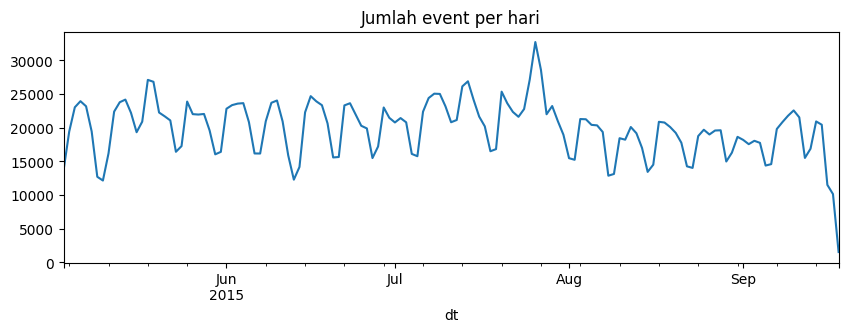

In [20]:
events = pd.read_csv(RAW)
events["dt"] = pd.to_datetime(events["timestamp"], unit="ms")    

print("Shape  :", events.shape)
print("Rentang:", events["dt"].min(), "->", events["dt"].max())
print("Visitor unik:", f"{events['visitorid'].nunique():,}", "| Item unik:", f"{events['itemid'].nunique():,}")

display(events.head())
display(events["event"].value_counts().to_frame("jumlah"))
display(events.isna().sum().to_frame("jumlah_NaN"))     # transactionid terisi hanya pada event 'transaction'

per_bulan = events.groupby([events["dt"].dt.to_period("M"), "event"]).size().unstack(fill_value=0)
display(per_bulan)

events.set_index("dt").resample("D").size().plot(figsize=(10, 3), title="Jumlah event per hari")
plt.show()

# 2. Filter Periode P1 dan P2, Simpan `.csv` (2.1 no. 1-2)

In [21]:
def to_ms(s):
    return int(pd.Timestamp(s, tz="UTC").timestamp() * 1000)

def filter_period(df, start, end):
    return df[(df["timestamp"] >= to_ms(start)) & (df["timestamp"] <= to_ms(end))]

# Validasi desain periode
assert to_ms(PERIODS["P1"][1]) < to_ms(PERIODS["P2"][0]), "P2 harus setelah P1 dan tidak tumpang tindih"
assert to_ms(PERIODS["P1"][0]) >= int(events["timestamp"].min()) - 1, "P1 di luar rentang data"
assert to_ms(PERIODS["P2"][1]) <= int(events["timestamp"].max()) + 1, "P2 di luar rentang data"

COLS = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
subsets = {}
for name, (a, b) in PERIODS.items():
    sub = filter_period(events, a, b)[COLS].copy()
    assert len(sub) > 0, f"{name} kosong, ubah periode"
    sub["transactionid"] = sub["transactionid"].astype("Int64")
    sub.to_csv(FILES[name], index=False)
    subsets[name] = sub

ringkas = pd.DataFrame({
    name: {
        "rentang": f"{PERIODS[name][0][:10]} s.d. {PERIODS[name][1][:10]}",
        "jumlah event": len(s),
        "visitor unik": s["visitorid"].nunique(),
        "item unik": s["itemid"].nunique(),
        **{f"event {e}": int((s["event"] == e).sum()) for e in ["view", "addtocart", "transaction"]},
    } for name, s in subsets.items()
})
display(ringkas)

u1, u2 = set(subsets["P1"]["visitorid"]), set(subsets["P2"]["visitorid"])
print(f"Visitor yang muncul di P1 dan P2 (dasar evaluasi): {len(u1 & u2):,}")
print("Berkas tersimpan:", {k: str(v) for k, v in FILES.items()})

,P1,P2
rentang,2015-05-15 s.d. 2015-06-15,2015-08-15 s.d. 2015-09-15
jumlah event,657282,581835
visitor unik,343090,325811
item unik,122076,117523
event view,636789,561850
event addtocart,15471,15180
event transaction,5022,4805


Visitor yang muncul di P1 dan P2 (dasar evaluasi): 6,905
Berkas tersimpan: {'P1': 'D:\\Graf SaDa\\UTS-Graf-Sains-Data\\data\\events_train_P1.csv', 'P2': 'D:\\Graf SaDa\\UTS-Graf-Sains-Data\\data\\events_test_P2.csv'}


# 3. Impor ke Neo4j

In [22]:
def reset_database():
    with driver.session(database=DATABASE) as s:
        s.run("MATCH ()-[r]->() CALL { WITH r DELETE r } IN TRANSACTIONS OF 50000 ROWS").consume()
        s.run("MATCH (n) CALL { WITH n DELETE n } IN TRANSACTIONS OF 50000 ROWS").consume()
    print("Database dikosongkan")

def create_constraints():
    for cy in [
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE",
        "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE",
    ]:
        run_write(cy)

def import_nodes(paths, batch=10_000):
    visitors, items = set(), set()
    for fp in paths:
        for ch in pd.read_csv(fp, usecols=["visitorid", "itemid"], chunksize=500_000):
            visitors.update(ch["visitorid"].unique().tolist())
            items.update(ch["itemid"].unique().tolist())
    for label, key, ids in [("Visitor", "visitorId", sorted(visitors)),
                            ("Item", "itemId", sorted(items))]:
        cy = f"UNWIND $ids AS id MERGE (:{label} {{{key}: id}})"
        for i in tqdm(range(0, len(ids), batch), desc=f"Simpul {label}"):
            run_write(cy, ids=ids[i:i + batch])

RELATION_QUERIES = {
    "view": """
        UNWIND $rows AS row
        MATCH (v:Visitor {visitorId: row.visitorid})
        MATCH (i:Item {itemId: row.itemid})
        CREATE (v)-[:VIEWED {timestamp: row.timestamp, period: row.period}]->(i)
    """,
    "addtocart": """
        UNWIND $rows AS row
        MATCH (v:Visitor {visitorId: row.visitorid})
        MATCH (i:Item {itemId: row.itemid})
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, period: row.period}]->(i)
    """,
    "transaction": """
        UNWIND $rows AS row
        MATCH (v:Visitor {visitorId: row.visitorid})
        MATCH (i:Item {itemId: row.itemid})
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, period: row.period,
                             transactionId: row.transactionid}]->(i)
    """,
}

def import_batch(tx, rows, event_type):
    tx.run(RELATION_QUERIES[event_type], rows=rows).consume()

def import_period(file_path, period, batch_size=5000):
    total = 0
    for chunk in tqdm(pd.read_csv(file_path, chunksize=batch_size), desc=f"Import {period}"):
        for event_type, g in chunk.groupby("event"):
            if event_type not in RELATION_QUERIES:
                continue
            records = [
                {"visitorid": int(v), "itemid": int(i), "timestamp": int(t), "period": period,
                 "transactionid": None if pd.isna(x) else int(x)}
                for v, i, t, x in zip(g["visitorid"], g["itemid"], g["timestamp"], g["transactionid"])
            ]
            with driver.session(database=DATABASE) as session:
                session.execute_write(import_batch, records, event_type)
            total += len(records)
    print(f"Total event diimpor untuk {period}: {total:,}")

def count_rels(period):
    return int(q("MATCH ()-[r]->() WHERE r.period = $p RETURN count(r) AS n", p=period)["n"][0])

def purge_period(period):
    """Hapus relasi satu periode (dipakai bila impor terputus dan perlu diulang)."""
    with driver.session(database=DATABASE) as s:
        s.run("MATCH ()-[r]->() WHERE r.period = $p "
              "CALL { WITH r DELETE r } IN TRANSACTIONS OF 10000 ROWS", p=period).consume()

if RESET_DB:
    reset_database()
create_constraints()
import_nodes(FILES.values())

for period, path in FILES.items():
    n = count_rels(period)
    if n > 0:
        print(f"{period}: sudah ada {n:,} relasi, dilewati. Jika impor sebelumnya terputus: purge_period('{period}') lalu jalankan ulang.")
        continue
    import_period(path, period, batch_size=5000)

Simpul Item: 100%|██████████| 18/18 [00:05<00:00,  3.54it/s]
Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `period` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=26, offset=25>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 25, 'line': 1, 'column': 26}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[r]->() WHERE r.period = $p RETURN count(r) AS n'
Import P1: 132it [01:41,  1.30it/s]


Total event diimpor untuk P1: 657,282


Import P2: 117it [01:25,  1.37it/s]

Total event diimpor untuk P2: 581,835


# 4.Komposisi Subgraph



In [23]:
CY_NODES = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label, count(*) AS jumlah
ORDER BY jumlah DESC
"""
CY_RELS = """
MATCH ()-[r]->()
WHERE r.period IS NOT NULL
RETURN r.period AS periode, type(r) AS relasi, count(*) AS jumlah
ORDER BY periode, relasi
"""
CY_ACTIVE = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN r.period AS periode,
       count(DISTINCT v) AS visitor_aktif,
       count(DISTINCT i) AS item_aktif,
       count(r)          AS total_relasi
ORDER BY periode
"""
df_nodes, df_rels, df_active = q(CY_NODES), q(CY_RELS), q(CY_ACTIVE)
display(df_nodes); display(df_rels); display(df_active)

,label,jumlah
0,Visitor,661996
1,Item,172773


,periode,relasi,jumlah
0,P1,ADDED_TO_CART,15471
1,P1,BOUGHT,5022
2,P1,VIEWED,636789
3,P2,ADDED_TO_CART,15180
4,P2,BOUGHT,4805
5,P2,VIEWED,561850


,periode,visitor_aktif,item_aktif,total_relasi
0,P1,343090,122076,657282
1,P2,325811,117523,581835


2.1 no 3
- Jenis simpul :
- Visitor (user) = 661.996
- Item = 172.773

- Relasi : P1 = 636.789   ;   P2 = 561.850
- ADDED_TO_CART : P1 = 15.471  ;   P2 = 15.180
- BOUGHT : P1 = 5.022  ;   P2 = 4.805

**Penjelasan CYPHER yang digunakan**

| Query | Penjelasan |
|-------|------------|
| CY_NODES | MATCH (n) memilih semua simpul. UNWIND labels(n) memecah daftar label menjadi baris, lalu count(*) dikelompokkan per label, sehingga diperoleh jenis simpul (Visitor, Item) dan jumlahnya. |
| CY_RELS | MATCH ()-[r]->() memilih semua relasi berarah. type(r) mengambil tipe relasi (VIEWED, ADDED_TO_CART, BOUGHT) dan r.period mengelompokkannya per periode. |
| CY_ACTIVE | Pola (Visitor)-[r]->(Item) menggambarkan graf bipartit. count(DISTINCT ...) menghitung simpul unik yang benar-benar memiliki interaksi pada tiap periode. |


## 5. Vector Space Modelling (2.1 no. 4-5)

,VSM User (baris X),VSM Item (kolom X)
Jumlah vektor,343090,122076
Dimensi tiap vektor,122076,343090
Shape matriks,343090 x 122076,122076 x 343090
Rata-rata entri nol-tidak per vektor,1.491,4.189
Median,1.0,2.0
Maks,1128,970
Proporsi vektor dengan 1 entri,0.8051,0.48
Memori matriks ternormalisasi (MB),5.5,4.6


nnz = 511,376 | densitas = 0.001221% | sparsitas = 99.9988%

Contoh vektor user 7 -> {226353: 1.0}


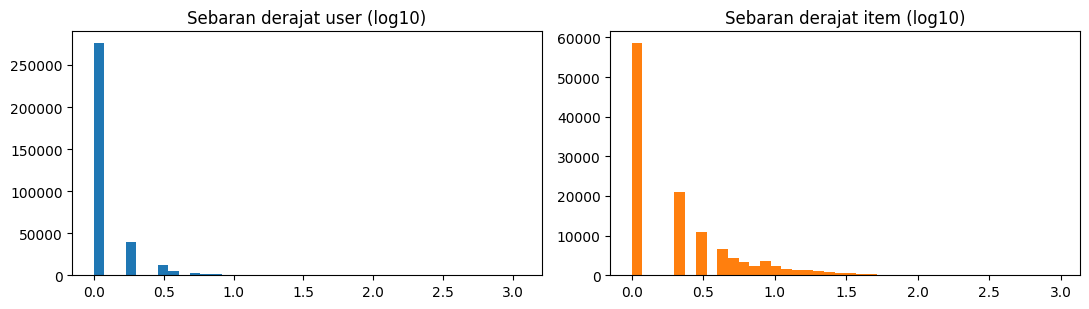

In [24]:
EDGE_QUERY = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.period = 'P1'
WITH v, i, sum(CASE type(r) WHEN 'VIEWED' THEN $w_view
                            WHEN 'ADDED_TO_CART' THEN $w_cart
                            ELSE $w_buy END) AS w
RETURN v.visitorId AS visitor, i.itemId AS item, w
"""
agg = q(EDGE_QUERY, w_view=WEIGHTS["VIEWED"], w_cart=WEIGHTS["ADDED_TO_CART"], w_buy=WEIGHTS["BOUGHT"])
assert len(agg) > 0, "Tidak ada relasi P1 di Neo4j. Periksa bagian impor."

u_cat = agg["visitor"].astype("category")
i_cat = agg["item"].astype("category")
user_ids = u_cat.cat.categories.to_numpy()
item_ids = i_cat.cat.categories.to_numpy()

X = csr_matrix(
    (agg["w"].to_numpy(dtype=np.float32),
     (u_cat.cat.codes.to_numpy(), i_cat.cat.codes.to_numpy())),
    shape=(len(user_ids), len(item_ids)),
)
Xn_user = normalize(X)                    
Xn_item = normalize(X.T.tocsr())         

n_u, n_i = X.shape
user_deg = np.diff(X.indptr).astype(np.int64)             # jumlah item unik per user
item_deg = np.diff(X.tocsc().indptr).astype(np.int64)     # jumlah user unik per item
density = X.nnz / (n_u * n_i)

def nbytes(m): return (m.data.nbytes + m.indices.nbytes + m.indptr.nbytes) / 1e6

tabel_vsm = pd.DataFrame({
    "VSM User (baris X)": {
        "Jumlah vektor": n_u, "Dimensi tiap vektor": n_i, "Shape matriks": f"{n_u} x {n_i}",
        "Rata-rata entri nol-tidak per vektor": round(user_deg.mean(), 3), "Median": float(np.median(user_deg)),
        "Maks": int(user_deg.max()), "Proporsi vektor dengan 1 entri": round(float((user_deg == 1).mean()), 4),
        "Memori matriks ternormalisasi (MB)": round(nbytes(Xn_user), 1),
    },
    "VSM Item (kolom X)": {
        "Jumlah vektor": n_i, "Dimensi tiap vektor": n_u, "Shape matriks": f"{n_i} x {n_u}",
        "Rata-rata entri nol-tidak per vektor": round(item_deg.mean(), 3), "Median": float(np.median(item_deg)),
        "Maks": int(item_deg.max()), "Proporsi vektor dengan 1 entri": round(float((item_deg == 1).mean()), 4),
        "Memori matriks ternormalisasi (MB)": round(nbytes(Xn_item), 1),
    },
})
display(tabel_vsm)
print(f"nnz = {X.nnz:,} | densitas = {density:.6%} | sparsitas = {1 - density:.4%}")

row0 = X.getrow(0)
print("\nContoh vektor user", user_ids[0], "->", dict(zip(item_ids[row0.indices].tolist(), row0.data.tolist())))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(np.log10(user_deg), bins=40, color="tab:blue"); ax[0].set_title("Sebaran derajat user (log10)")
ax[1].hist(np.log10(item_deg), bins=40, color="tab:orange"); ax[1].set_title("Sebaran derajat item (log10)")
plt.tight_layout(); plt.show()

Bipartit : 57 simpul, 63 sisi
User-User: 25 simpul, 300 sisi
Item-Item: 32 simpul, 109 sisi


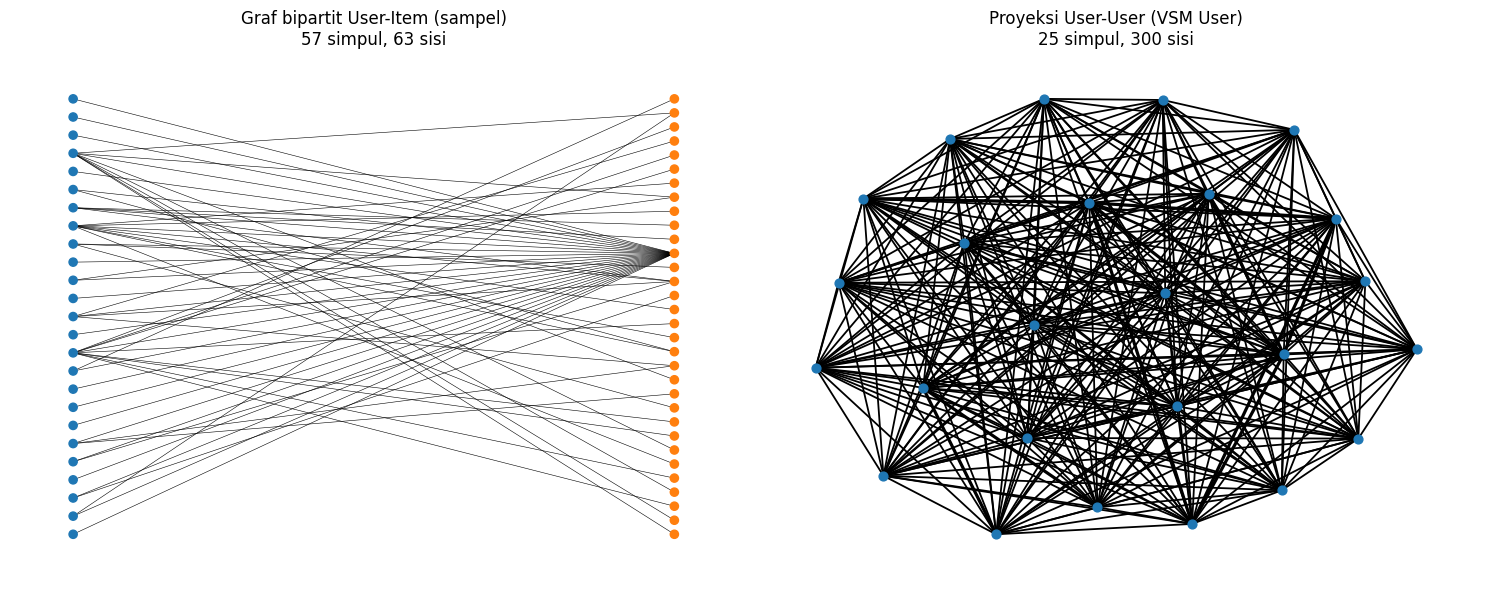

In [25]:
def sample_subgraph(n_users=25, max_items_per_user=8, seed=SEED):
    rng = np.random.default_rng(seed)
    csc = X.tocsc()
    cand = np.where((item_deg >= 10) & (item_deg <= 60))[0]
    if len(cand) == 0:
        cand = np.where(item_deg >= 2)[0]
    seed_item = int(rng.choice(cand))
    users = csc[:, seed_item].nonzero()[0][:n_users]
    edges = []
    for u in users:
        row = X.getrow(u)
        top = row.indices[np.argsort(-row.data)[:max_items_per_user]]
        top = set(top.tolist()) | {seed_item}
        w = dict(zip(row.indices.tolist(), row.data.tolist()))
        edges += [(int(u), int(i), float(w[i])) for i in top]
    return edges, seed_item

edges, seed_item = sample_subgraph()
U_nodes = sorted({f"U{user_ids[u]}" for u, _, _ in edges})
I_nodes = sorted({f"I{item_ids[i]}" for _, i, _ in edges})

B = nx.Graph()
B.add_nodes_from(U_nodes, bipartite=0)
B.add_nodes_from(I_nodes, bipartite=1)
B.add_weighted_edges_from((f"U{user_ids[u]}", f"I{item_ids[i]}", w) for u, i, w in edges)
PU = nx.bipartite.weighted_projected_graph(B, U_nodes)     # proyeksi User-User
PI = nx.bipartite.weighted_projected_graph(B, I_nodes)     # proyeksi Item-Item
print("Bipartit :", B.number_of_nodes(), "simpul,", B.number_of_edges(), "sisi")
print("User-User:", PU.number_of_nodes(), "simpul,", PU.number_of_edges(), "sisi")
print("Item-Item:", PI.number_of_nodes(), "simpul,", PI.number_of_edges(), "sisi")

def plot_vsm(proj, nodes, color, title):
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    pos = nx.bipartite_layout(B, U_nodes)
    nx.draw(B, pos, ax=ax[0], node_size=35, width=0.4,
            node_color=["tab:blue" if n in set(U_nodes) else "tab:orange" for n in B])
    ax[0].set_title(f"Graf bipartit User-Item (sampel)\n{B.number_of_nodes()} simpul, {B.number_of_edges()} sisi")
    w = [d["weight"] for _, _, d in proj.edges(data=True)] or [1]
    nx.draw(proj, nx.spring_layout(proj, seed=SEED), ax=ax[1], node_size=40,
            width=[0.3 + 2.0 * x / max(w) for x in w], node_color=color)
    ax[1].set_title(f"{title}\n{proj.number_of_nodes()} simpul, {proj.number_of_edges()} sisi")
    plt.tight_layout(); plt.show()

# 2.1 no. 4: VSM User
plot_vsm(PU, U_nodes, "tab:blue", "Proyeksi User-User (VSM User)")

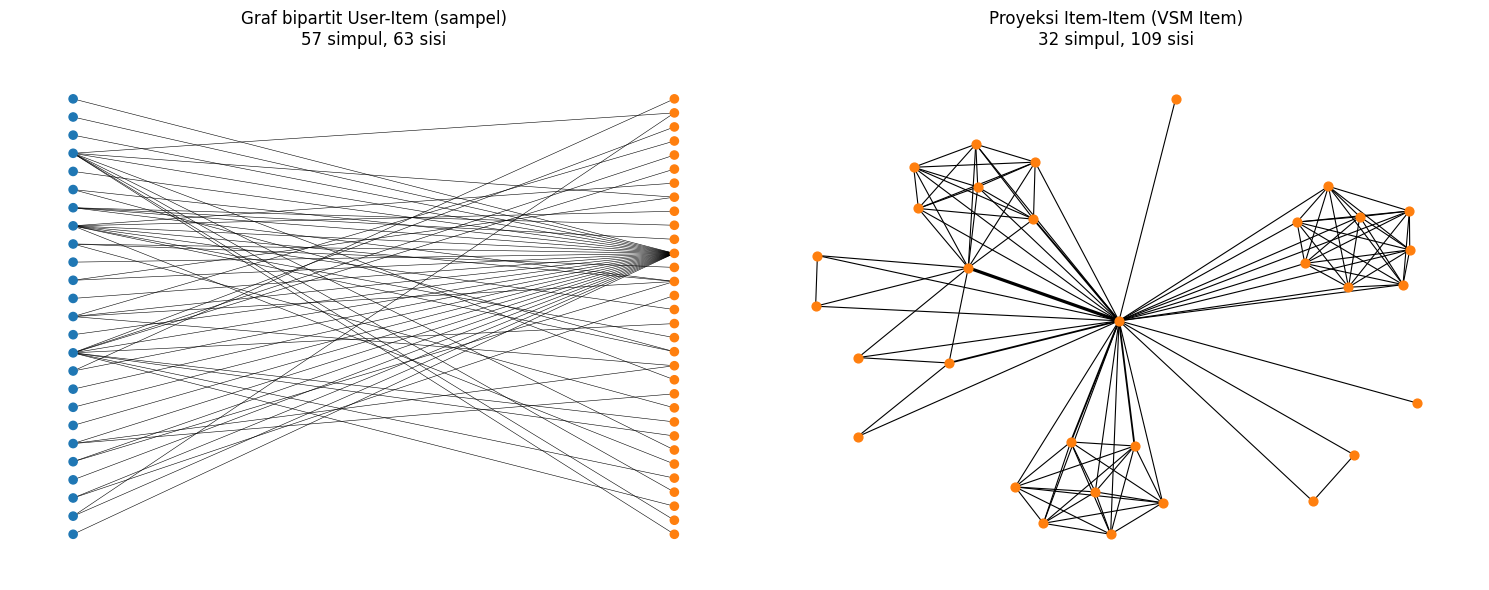

In [26]:
plot_vsm(PI, I_nodes, "tab:orange", "Proyeksi Item-Item (VSM Item)")

4. Plot networkx: graf bipartit sampel (57 simpul, 63 sisi) dan proyeksi User-User (25 simpul, 300 sisi). Perhatikan bahwa 300 = C(25,2), yaitu graf lengkap. Itu artefak sampling: 25 user diambil dari satu item benih yang sama, sehingga semuanya saling terhubung. Tulis di laporan bahwa ini bukan sifat data keseluruhan.
5. Plot: proyeksi Item-Item sampel 32 simpul dan 109 sisi (dari bipartit 57 simpul, 63 sisi). Sebaran derajat berekor panjang, yaitu sedikit item sangat populer dan banyak item jarang.


In [34]:
K = 5                 # jumlah tetangga terdekat
TOPN = 5              # panjang daftar rekomendasi 
N_ADS = 3             # item yang diiklankan 
EXCLUDE_SEEN = True
MAX_HIST = 50         # batas item riwayat yang dipakai pada KNN berbasis item

user_pos = pd.Series(np.arange(n_u), index=user_ids)
item_pos = pd.Series(np.arange(n_i), index=item_ids)

# ---- Ground truth dari P2 ----
test_df = pd.read_csv(FILES["P2"], usecols=["visitorid", "itemid"])
t = pd.DataFrame({"u": test_df["visitorid"].map(user_pos), "i": test_df["itemid"].map(item_pos)}).dropna().astype(int)
truth = {int(u): set(map(int, g)) for u, g in t.groupby("u")["i"]}
eligible = np.array(sorted(u for u in truth if user_deg[u] >= 2))
print(f"User berhak dievaluasi (ada di P1 dengan >=2 item dan punya item relevan di P2): {len(eligible):,}")

ENT = {
    "user": dict(label="Visitor", key="visitorId", ids=user_ids, Mn=Xn_user, deg=user_deg, prefix="U"),
    "item": dict(label="Item", key="itemId", ids=item_ids, Mn=Xn_item, deg=item_deg, prefix="I"),
}

def topk_sim(Mn, idx, k):    
    sims = (Mn @ Mn[idx].T).toarray().ravel()
    sims[idx] = -1.0
    k = min(k, len(sims) - 1)
    top = np.argpartition(-sims, k)[:k]
    top = top[np.argsort(-sims[top])]
    top = top[sims[top] > 0]
    return top, sims[top]

def _rank(scores, seen, n):
    if EXCLUDE_SEEN and len(seen):
        scores[seen] = -np.inf
    n = min(n, len(scores) - 1)
    top = np.argpartition(-scores, n)[:n]
    top = top[np.argsort(-scores[top])]
    top = top[scores[top] > 0]
    return top, scores[top]

def recommend_user_knn(u, k=K, n=TOPN):
    nb, sim = topk_sim(Xn_user, u, k)
    if len(nb) == 0:
        return {"items": np.array([], dtype=int), "scores": np.array([]), "neighbors": (nb, sim)}
    scores = np.asarray(Xn_user[nb].T.dot(sim)).ravel()
    top, sc = _rank(scores, X[u].indices, n)
    return {"items": top, "scores": sc, "neighbors": (nb, sim)}

def recommend_item_knn(u, k=K, n=TOPN):
    row = X[u]
    H, w = row.indices, row.data
    if len(H) > MAX_HIST:
        keep = np.argsort(-w)[:MAX_HIST]
        H, w = H[keep], w[keep]
    S = (Xn_item[H] @ Xn_item.T).tocsr()
    scores = np.zeros(n_i, dtype=np.float64)
    for r, (h, wt) in enumerate(zip(H, w)):
        s = S.getrow(r)
        idx, dat = s.indices, s.data.copy()
        m = idx != h
        idx, dat = idx[m], dat[m]
        if len(dat) > k:
            tt = np.argpartition(-dat, k)[:k]
            idx, dat = idx[tt], dat[tt]
        scores[idx] += np.log1p(wt) * dat
    top, sc = _rank(scores, row.indices, n)
    return {"items": top, "scores": sc, "neighbors": None}

RECOMMENDERS = {"user": recommend_user_knn, "item": recommend_item_knn}

# ---- Metrik (relevansi biner) ----
def hit_at_k(rec, rel, k=TOPN):
    return int(len(set(rec[:k]) & rel) > 0)

def ndcg_at_k(rec, rel, k=TOPN):
    dcg = sum(1.0 / math.log2(i + 2) for i, it in enumerate(rec[:k]) if it in rel)
    idcg = sum(1.0 / math.log2(i + 2) for i in range(min(k, len(rel))))
    return dcg / idcg if idcg > 0 else 0.0

def evaluate(recfn, users, k=K, n=TOPN):
    hits, ndcgs, times = [], [], []
    for u in users:
        t0 = time.perf_counter()
        r = recfn(int(u), k=k, n=n)
        times.append(time.perf_counter() - t0)
        rel = truth[int(u)]
        rec = [int(x) for x in r["items"]]
        hits.append(hit_at_k(rec, rel, n)); ndcgs.append(ndcg_at_k(rec, rel, n))
    return {"Hit@5": float(np.mean(hits)), "NDCG@5": float(np.mean(ndcgs)),
            "detik/user": float(np.mean(times)), "n_user": len(users)}


def write_similarity(ent, ref_id, pairs):
    L, Kk = ENT[ent]["label"], ENT[ent]["key"]
    cy = f"""
    MATCH (a:{L} {{{Kk}: $ref}})
    UNWIND $pairs AS p
    MATCH (b:{L} {{{Kk}: p.id}})
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.score = p.score, s.metric = 'cosine', s.basis = 'P1', s.entity = $ent
    """
    run_write(cy, ref=int(ref_id), pairs=pairs, ent=ent)

def ego_edges(ent, ids, per_node=8):
    if ent == "user":
        cy = """
        MATCH (n:Visitor) WHERE n.visitorId IN $ids
        CALL { WITH n MATCH (n)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(m:Item)
               WHERE r.period = 'P1' RETURN m, type(r) AS rel LIMIT $lim }
        RETURN n.visitorId AS a, m.itemId AS b, rel
        """
    else:
        cy = """
        MATCH (n:Item) WHERE n.itemId IN $ids
        CALL { WITH n MATCH (m:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(n)
               WHERE r.period = 'P1' RETURN m, type(r) AS rel LIMIT $lim }
        RETURN n.itemId AS a, m.visitorId AS b, rel
        """
    return q(cy, ids=[int(i) for i in ids], lim=per_node)

User berhak dievaluasi (ada di P1 dengan >=2 item dan punya item relevan di P2): 2,124


### . Perbandingan Proyeksi: Efektif dan Efisien (2.1 no. 6)




In [35]:
est_uu = int((item_deg * (item_deg - 1) // 2).sum())
est_ii = int((user_deg * (user_deg - 1) // 2).sum())
max_uu, max_ii = n_u * (n_u - 1) // 2, n_i * (n_i - 1) // 2

struktur = pd.DataFrame({
    "Proyeksi User-User": {"Simpul": n_u, "Dimensi vektor": n_i, "Estimasi sisi (batas atas)": est_uu,
                           "Rasio thd graf lengkap": est_uu / max_uu, "Memori (MB)": round(nbytes(Xn_user), 1)},
    "Proyeksi Item-Item": {"Simpul": n_i, "Dimensi vektor": n_u, "Estimasi sisi (batas atas)": est_ii,
                           "Rasio thd graf lengkap": est_ii / max_ii, "Memori (MB)": round(nbytes(Xn_item), 1)},
})
display(struktur)

N_EVAL = min(300, len(eligible))
sample_eval = np.random.default_rng(SEED + 1).choice(eligible, size=N_EVAL, replace=False)
res = {name: evaluate(fn, sample_eval) for name, fn in RECOMMENDERS.items()}
hasil_banding = pd.DataFrame(res).T
hasil_banding.index = ["User-User (KNN user)", "Item-Item (KNN item)"]
display(hasil_banding)

CHOSEN_OVERRIDE = None        # isi "user" atau "item" untuk memaksa pilihan
CHOSEN = CHOSEN_OVERRIDE or ("user" if res["user"]["NDCG@5"] >= res["item"]["NDCG@5"] else "item")
print(f"Proyeksi terpilih: {CHOSEN.upper()}-{CHOSEN.upper()}")

,Proyeksi User-User,Proyeksi Item-Item
Simpul,3.430900e+05,1.220760e+05
Dimensi vektor,1.220760e+05,3.430900e+05
Estimasi sisi (batas atas),6.997000e+06,4.013456e+06
Rasio thd graf lengkap,1.188850e-04,5.386312e-04
Memori (MB),5.500000e+00,4.600000e+00


,Hit@5,NDCG@5,detik/user,n_user
User-User (KNN user),0.003333,0.001290,0.026858,300.0
Item-Item (KNN item),0.010000,0.002819,0.038245,300.0


Proyeksi terpilih: ITEM-ITEM


6. Kesimpulan: Item-Item lebih baik secara struktur (simpul 2,8x lebih sedikit, sisi 1,7x lebih sedikit) dan lebih efektif, namun waktu per query Item-Item lebih lambat karena harus menelusuri tiap item riwayat user; selisih Hit@5 setara 3 user berbanding 1 dari 300, sehingga keunggulan efektivitas hanya berupa indikasi dan belum kuat secara statistik. Alasan tambahan: 80,5% user hanya punya 1 item, sehingga vektor user hampir tak informatif, sedangkan vektor item lebih padat (rata-rata 4,2 user)

## 7. Similarity pada Proyeksi Terpilih (2.1 no. 7)


(a) Cypher: UNWIND $pairs AS p MATCH (n:Item {itemId: p.id}) OPTIONAL MATCH (n)-[r:VIEWED|ADDED_TO_CART|BOUGHT]-() WHERE r.period='P1' WITH n, p.score AS similarity, count(r) AS interaksi_P1 RETURN n.itemId AS id, similarity, interaksi_P1 ORDER BY similarity DESC LIMIT 5

(b) Penulisan ke graf: MATCH (a:Item {itemId:$ref}) UNWIND $pairs AS p MATCH (b:Item {itemId:p.id}) MERGE (a)-[s:SIMILAR_TO]->(b) SET s.score = p.score, s.metric='cosine', s.basis='P1'. Query pembuktian MATCH (a:Item {itemId:$ref})-[s:SIMILAR_TO]->(b:Item) RETURN ... mengembalikan lima baris acuan 43330 dengan skor di atas (tabel sim_edges).

In [36]:
E = ENT[CHOSEN]
L, KEY = E["label"], E["key"]

# Reset relasi similarity agar kondisi "sebelum" selalu bersih dan sel dapat dijalankan ulang
run_write("MATCH ()-[s:SIMILAR_TO]->() DELETE s")
n_sim_before = int(q("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n")["n"][0])

# Record acuan: dipilih acak dengan seed (reproducible) dari simpul berderajat >= 5
rng = np.random.default_rng(SEED)
ref = int(rng.choice(np.where(E["deg"] >= 5)[0]))
ref_id = int(E["ids"][ref])
print(f"Entitas: {CHOSEN} | acuan: {L} {ref_id} (derajat {E['deg'][ref]})")

# Perhitungan similarity (Python)
nb, sc = topk_sim(E["Mn"], ref, 50)
pairs = [{"id": int(E["ids"][j]), "score": float(s)} for j, s in zip(nb, sc)]
display(pd.DataFrame(pairs).head(10).rename(columns={"id": f"{KEY}", "score": "cosine"}))

# (a) CYPHER: 5 record dengan similarity tertinggi
CY_TOP5 = f"""
UNWIND $pairs AS p
MATCH (n:{L} {{{KEY}: p.id}})
OPTIONAL MATCH (n)-[r:VIEWED|ADDED_TO_CART|BOUGHT]-()
WHERE r.period = 'P1'
WITH n, p.score AS similarity, count(r) AS interaksi_P1
RETURN n.{KEY} AS id, similarity, interaksi_P1
ORDER BY similarity DESC
LIMIT 5
"""
top5 = q(CY_TOP5, pairs=pairs)
display(top5)

top5_pairs = [{"id": int(r.id), "score": float(r.similarity)} for r in top5.itertuples()]
focus_ids = [ref_id] + [p["id"] for p in top5_pairs]

# Simpan kondisi SEBELUM penulisan similarity (dipakai pada bagian 8)
edges_before = ego_edges(CHOSEN, focus_ids)

# (b) CYPHER: tulis kembali nilai similarity ke graf
CY_WRITE = f"""
MATCH (a:{L} {{{KEY}: $ref}})
UNWIND $pairs AS p
MATCH (b:{L} {{{KEY}: p.id}})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = p.score, s.metric = 'cosine', s.basis = 'P1', s.entity = $ent
"""
run_write(CY_WRITE, ref=ref_id, pairs=top5_pairs, ent=CHOSEN)

# Hasil query setelah penulisan
CY_READ_SIM = f"""
MATCH (a:{L} {{{KEY}: $ref}})-[s:SIMILAR_TO]->(b:{L})
RETURN a.{KEY} AS acuan, b.{KEY} AS tetangga, s.score AS similarity, s.metric AS metrik
ORDER BY similarity DESC
"""
sim_edges = q(CY_READ_SIM, ref=ref_id)
display(sim_edges)

Entitas: item | acuan: Item 43330 (derajat 24)


,itemId,cosine
0,449822,0.339950
1,239065,0.274721
2,115723,0.194257
3,103776,0.168232
4,209887,0.155752
5,403615,0.137361
6,303367,0.137361
7,439085,0.135696
8,64657,0.133259
9,58576,0.132175


,id,similarity,interaksi_P1
0,449822,0.339950,22
1,239065,0.274721,1
2,115723,0.194257,2
3,103776,0.168232,14
4,209887,0.155752,7


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=3, column=9, offset=55>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 55, 'line': 3, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        MATCH (n:Item) WHERE n.itemId IN $ids\n        CALL { WITH n MATCH (m:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(n)\n               WHERE r.period = 'P1' RETURN m, type(r) AS rel LIMIT $lim }\n        RETURN n.itemId AS a, m.visitorId AS b, rel\n        "


,acuan,tetangga,similarity,metrik
0,43330,449822,0.339950,cosine
1,43330,239065,0.274721,cosine
2,43330,115723,0.194257,cosine
3,43330,103776,0.168232,cosine
4,43330,209887,0.155752,cosine


## 8. Graf Sebelum dan Sesudah Perhitungan Similarity (2.1 no. 8)

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=3, column=9, offset=55>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 55, 'line': 3, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        MATCH (n:Item) WHERE n.itemId IN $ids\n        CALL { WITH n MATCH (m:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(n)\n               WHERE r.period = 'P1' RETURN m, type(r) AS rel LIMIT $lim }\n        RETURN n.itemId AS a, m.visitorId AS b, rel\n        "


Relasi SIMILAR_TO  sebelum: 0 | sesudah: 5


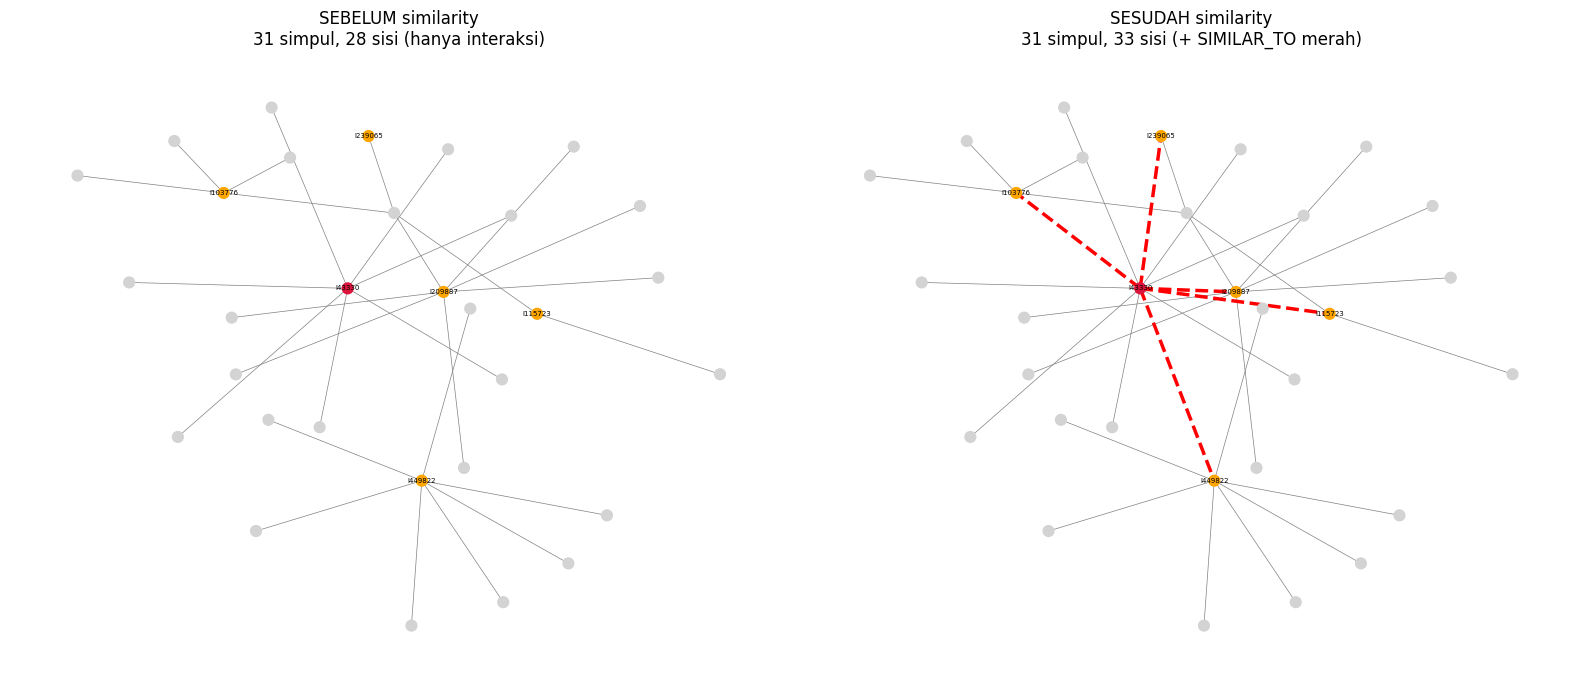

In [37]:
CY_COUNT_SIM = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_relasi_similarity"
n_sim_after = int(q(CY_COUNT_SIM)["jumlah_relasi_similarity"][0])
print(f"Relasi SIMILAR_TO  sebelum: {n_sim_before} | sesudah: {n_sim_after}")

edges_after = ego_edges(CHOSEN, focus_ids)      # relasi interaksi (tidak berubah)

pf = E["prefix"]; other = "I" if CHOSEN == "user" else "U"
def build_graph(with_sim):
    G = nx.Graph()
    for r in edges_after.itertuples():
        G.add_edge(f"{pf}{r.a}", f"{other}{r.b}", kind="interaksi", score=0)
    if with_sim:
        for r in sim_edges.itertuples():
            G.add_edge(f"{pf}{r.acuan}", f"{pf}{r.tetangga}", kind="sim", score=r.similarity)
    return G

G_after = build_graph(True)
G_before = build_graph(False)
pos = nx.spring_layout(G_after, seed=SEED, k=0.7)

def draw(ax, G, title):
    nbr = {f"{pf}{i}" for i in focus_ids[1:]}
    colors = ["crimson" if n == f"{pf}{ref_id}" else "orange" if n in nbr
              else "tab:blue" if n.startswith(pf) else "lightgray" for n in G]
    sim_e = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] == "sim"]
    int_e = [(u, v) for u, v, d in G.edges(data=True) if d["kind"] == "interaksi"]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=60)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=int_e, width=0.5, edge_color="gray")
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=sim_e, width=2.5, edge_color="red", style="dashed")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=5,
                            labels={n: n for n in G if n.startswith(pf) and (n in nbr or n == f"{pf}{ref_id}")})
    ax.set_title(title); ax.axis("off")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
draw(ax[0], G_before, f"SEBELUM similarity\n{G_before.number_of_nodes()} simpul, {G_before.number_of_edges()} sisi (hanya interaksi)")
draw(ax[1], G_after, f"SESUDAH similarity\n{G_after.number_of_nodes()} simpul, {G_after.number_of_edges()} sisi (+ SIMILAR_TO merah)")
plt.tight_layout(); plt.show()

- Sebelum Relasi SIMILAR_TO sebelum: 0	31 simpul, 28 sisi (hanya interaksi)
- Sesudah Relasi SIMILAR_TO sesudah: 5	31 simpul, 33 sisi (+5 garis merah putus-putus dari 43330 ke tetangganya)

## 9. Analytics: KNN, Item Iklan, Hit@5, NDCG@5 (2.2)

In [38]:
recommend = RECOMMENDERS[CHOSEN]

# 1. Pilih user acak (reproducible)
target = int(np.random.default_rng(SEED).choice(eligible))
target_id = int(user_ids[target])
print(f"User terpilih: visitorId={target_id} | item unik di P1: {user_deg[target]} | item relevan di P2: {len(truth[target])}")
print("Metode rekomendasi:", "KNN berbasis user" if CHOSEN == "user" else "KNN berbasis item", f"(k={K})")

# 1a. Skrip rekomendasi KNN (fungsi recommend_user_knn / recommend_item_knn pada bagian Fungsi Inti)
r = recommend(target, k=K, n=TOPN)
rec = [int(x) for x in r["items"]]
rel = truth[target]

if r["neighbors"] is not None:
    nb, sim = r["neighbors"]
    display(pd.DataFrame({"tetangga (visitorId)": user_ids[nb], "cosine": sim}))
    write_similarity("user", target_id, [{"id": int(user_ids[j]), "score": float(s)} for j, s in zip(nb, sim)])

# 1b. Daftar rekomendasi dan 3 item yang diiklankan
daftar = pd.DataFrame({
    "peringkat": np.arange(1, len(rec) + 1),
    "itemId": item_ids[rec],
    "skor": np.round(r["scores"], 4),
    "relevan di P2?": [it in rel for it in rec],
    "diiklankan": ["ya" if i < N_ADS else "" for i in range(len(rec))],
})
display(daftar)
print("3 item yang diiklankan:", item_ids[rec[:N_ADS]].tolist())

# 2. Hit@5 dan NDCG@5 (perhitungan rinci)
rinci = pd.DataFrame({
    "peringkat i": np.arange(1, len(rec) + 1),
    "rel_i": [int(it in rel) for it in rec],
    "diskon 1/log2(i+1)": [round(1 / math.log2(i + 2), 4) for i in range(len(rec))],
})
rinci["gain"] = (rinci["rel_i"] * rinci["diskon 1/log2(i+1)"]).round(4)
display(rinci)

dcg = float(rinci["gain"].sum())
idcg = sum(1.0 / math.log2(i + 2) for i in range(min(TOPN, len(rel))))
print(f"Hit@5  = {hit_at_k(rec, rel):d}")
print(f"DCG@5  = {dcg:.4f} | IDCG@5 = {idcg:.4f} | NDCG@5 = {ndcg_at_k(rec, rel):.4f}")

User terpilih: visitorId=123318 | item unik di P1: 2 | item relevan di P2: 2
Metode rekomendasi: KNN berbasis item (k=5)


,peringkat,itemId,skor,relevan di P2?,diiklankan
0,1,410321,0.4765,False,ya
1,2,407884,0.4765,False,ya
2,3,360684,0.4765,False,ya
3,4,346286,0.4765,False,
4,5,320826,0.4765,False,


3 item yang diiklankan: [410321, 407884, 360684]


,peringkat i,rel_i,diskon 1/log2(i+1),gain
0,1,0,1.0000,0.0
1,2,0,0.6309,0.0
2,3,0,0.5000,0.0
3,4,0,0.4307,0.0
4,5,0,0.3869,0.0


Hit@5  = 0
DCG@5  = 0.0000 | IDCG@5 = 1.6309 | NDCG@5 = 0.0000


1(a). Proses acak: np.random.default_rng(42).choice(eligible), reproducible. User terpilih: visitorId 123318 (2 item unik di P1, 2 item relevan di P2). Skrip: fungsi recommend_item_knn(u, k=5, n=5) pada sel 12 (kode lengkapnya ada di draf saya sebelumnya).

1(b). Tiga item yang diiklankan (k=5): 410321, 407884, 360684. Dua kandidat tambahan: 346286 dan 320826. Seluruh skor sama (0,4765), sehingga urutannya hanya hasil pemutus seri.

In [39]:
N_EVAL_FINAL = min(500, len(eligible))
users_eval = np.random.default_rng(SEED + 7).choice(eligible, size=N_EVAL_FINAL, replace=False)
hasil_final = evaluate(recommend, users_eval)
display(pd.DataFrame(hasil_final, index=[f"KNN {CHOSEN} (k={K})"]).round(4))

,Hit@5,NDCG@5,detik/user,n_user
KNN item (k=5),0.006,0.0015,0.0524,500


Interpretasi: riwayat user hanya 2 item (cold-start), kelima kandidat memiliki skor identik (0,476539), dan setiap kandidat hanya punya 1 user di P1, sehingga sinyalnya lemah. Irisan item relevan dengan riwayat P1 kosong, jadi EXCLUDE_SEEN bukan penyebabnya. Pada 500 user, KNN mencapai Hit@5 = 0,006 dan NDCG@5 = 0,0015, sedangkan baseline populer 0,0 dan 0,0. Jadi nilainya kecil, tetapi KNN masih lebih baik dari baseline. Nilai kecil ini wajar untuk data sangat sparse dengan jeda dua bulan.

In [40]:
seen = set(X[target].indices.tolist())
print("Item riwayat P1     :", item_ids[sorted(seen)].tolist())
print("Item relevan P2     :", item_ids[sorted(rel)].tolist())
print("Irisan relevan & P1 :", rel & seen)
print("Skor unik di top-5  :", np.unique(np.round(r["scores"], 6)))
print("Popularitas rekomendasi (user unik di P1):", item_deg[rec].tolist())
print("Popularitas item relevan                 :", item_deg[sorted(rel)].tolist())

# Pembanding sederhana: rekomendasi populer (baseline)
pop = np.argsort(-item_deg)
def recommend_popular(u, k=K, n=TOPN):
    s = set(X[u].indices.tolist())
    top = [i for i in pop[: n + len(s)] if i not in s][:n]
    return {"items": np.array(top), "scores": item_deg[top].astype(float), "neighbors": None}

print("Baseline populer:", evaluate(recommend_popular, users_eval))
print("KNN terpilih    :", hasil_final)

Item riwayat P1     : [229205, 397919]
Item relevan P2     : [28116, 53589]
Irisan relevan & P1 : set()
Skor unik di top-5  : [0.476539]
Popularitas rekomendasi (user unik di P1): [1, 1, 1, 1, 1]
Popularitas item relevan                 : [2, 2]
Baseline populer: {'Hit@5': 0.0, 'NDCG@5': 0.0, 'detik/user': 0.0002718913881108165, 'n_user': 500}
KNN terpilih    : {'Hit@5': 0.006, 'NDCG@5': 0.0015410038925448837, 'detik/user': 0.05242832461092621, 'n_user': 500}


# Eksplorasi Hasil

a. Irisan kosong. Item yang diakses user 123318 di P2 (28116, 53589) berbeda dari riwayat P1 (229205, 397919). Pengecualian item yang sudah dilihat (EXCLUDE_SEEN) tidak menjadi penyebab kegagalan. Minat user memang bergeser ke item yang belum pernah ia sentuh.

b. Skor seri penuh. Satu nilai skor untuk lima kandidat berarti urutan 1 sampai 5 hanya ditentukan oleh urutan indeks (pemutus seri), bukan oleh kualitas. NDCG pada user ini tidak informatif secara urutan, dan hasil Hit/NDCG-nya tidak boleh ditafsirkan sebagai “model kurang pintar mengurutkan”.

c. Popularitas rekomendasi = 1. Setiap item rekomendasi hanya pernah diakses oleh satu user di P1, yaitu satu tetangga yang kebetulan berbagi item dengan user target. Bukti kolaboratifnya sangat tipis: satu orang. Item dengan dukungan setipis itu hampir tidak punya peluang muncul lagi dua bulan kemudian.

d. Popularitas item relevan = 2. Ground truth user ini juga item ekor panjang (masing-masing 2 user di P1). Targetnya sendiri sulit ditebak oleh metode berbasis kemunculan bersama, dan kedua item itu tidak berbagi pengakses dengan riwayat user, sehingga tidak terjangkau tetangga item.

e. Hasil agregat 500 user. Hit@5 = 0,006 berarti 3 dari 500 user memperoleh minimal satu item tepat. Ketidakpastiannya besar: perkiraan selang kepercayaan 95% (Wilson) sekitar 0,2% sampai 1,7%. Nilai ini rendah secara absolut, tetapi layak dibandingkan dengan tebakan acak: dengan 122.076 item dan 5 slot, peluang Hit@5 acak untuk user dengan 2 item relevan hanya sekitar 0,008%. Perkiraan kasar ini menempatkan KNN pada orde puluhan kali di atas tebakan acak, meski masih kecil.

f. KNN versus baseline populer. KNN (3 hit) unggul atas baseline populer (0 hit), yang menunjukkan struktur graf memberi sinyal tambahan dibanding sekadar popularitas. Namun selisihnya hanya 3 user dari 500, jadi tulis sebagai indikasi, bukan bukti kuat. Baseline populer gagal karena item terpopuler di Mei-Juni tidak otomatis populer di Agustus-September, dan minat user tersebar di ekor panjang. Ada pula trade-off waktu: baseline sekitar 190 kali lebih cepat (0,0003 detik berbanding 0,05 detik per user).

Evaluasi pada 500 user acak (seed tetap) menghasilkan Hit@5 = 0,006 dan NDCG@5 = 0,0015 untuk KNN berbasis item (k=5), sedangkan baseline populer menghasilkan 0 pada kedua metrik. Nilai yang rendah disebabkan oleh sparsitas ekstrem (99,9988%), dominasi user dengan satu item (80,5%), jeda dua bulan antara periode latih dan uji, serta ground truth yang berada pada ekor panjang katalog. Pada user contoh (visitorId 123318), seluruh kandidat memiliki skor yang sama dan hanya didukung satu user di P1, sehingga tidak ada item relevan yang terambil. Meskipun kecil, hasil KNN lebih baik daripada baseline populer, yang mengindikasikan adanya sinyal dari struktur graf, tetapi selisih tiga user dari 500 belum cukup untuk kesimpulan yang kuat.

In [ ]:
OUT = DATA.parent / "hasil"
OUT.mkdir(exist_ok=True)

df_nodes.to_csv(OUT / "komposisi_simpul.csv", index=False)
df_rels.to_csv(OUT / "komposisi_relasi.csv", index=False)
df_active.to_csv(OUT / "simpul_aktif_per_periode.csv", index=False)
tabel_vsm.to_csv(OUT / "karakteristik_vsm.csv")
struktur.to_csv(OUT / "perbandingan_proyeksi_struktur.csv")
hasil_banding.to_csv(OUT / "perbandingan_proyeksi_evaluasi.csv")
daftar.to_csv(OUT / "rekomendasi_user_terpilih.csv", index=False)
sim_edges.to_csv(OUT / "similarity_top5.csv", index=False)
pd.DataFrame(hasil_final, index=[f"KNN {CHOSEN} (k={K})"]).to_csv(OUT / "evaluasi_500_user.csv")

# requirements.txt TIDAK ditimpa: pakai berkas yang sudah ada di folder proyek
(DATA.parent / ".gitignore").write_text(
    ".venv/\n__pycache__/\n.ipynb_checkpoints/\n"
    "data/events.csv\ndata/item_properties_part1.csv\n"
    "data/item_properties_part2.csv\ndata/category_tree.csv\n", encoding="utf-8")

print("Tersimpan di:", OUT)
      # jalankan sel ini PALING AKHIR